In [ ]:
!pip install scanpy scikit-misc igraph louvain leidenalg gseapy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 39.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 64.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.6/183.6 kB 15.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.4/4.4 MB 71.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 45.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 601.3/601.3 kB 34.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 169.9/169.9 kB 14.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.2/58.2 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 276.4/276.4 kB 18.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 70.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.5/53.5 kB 3.7 MB/s eta 0:00:00
  Created wheel for louvain: filename=louvain-0.8.2-cp312-cp312-linux_x86_64.whl size=971851

In [ ]:
#2 Imports
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import scanpy as sc
import scipy.sparse as sp
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import gseapy as gp

In [ ]:
#3 Load PBMC3k dataset
adata = sc.datasets.pbmc3k()
print(adata)

  0%|          | 0.00/5.58M [00:00<?, ?B/s]

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'


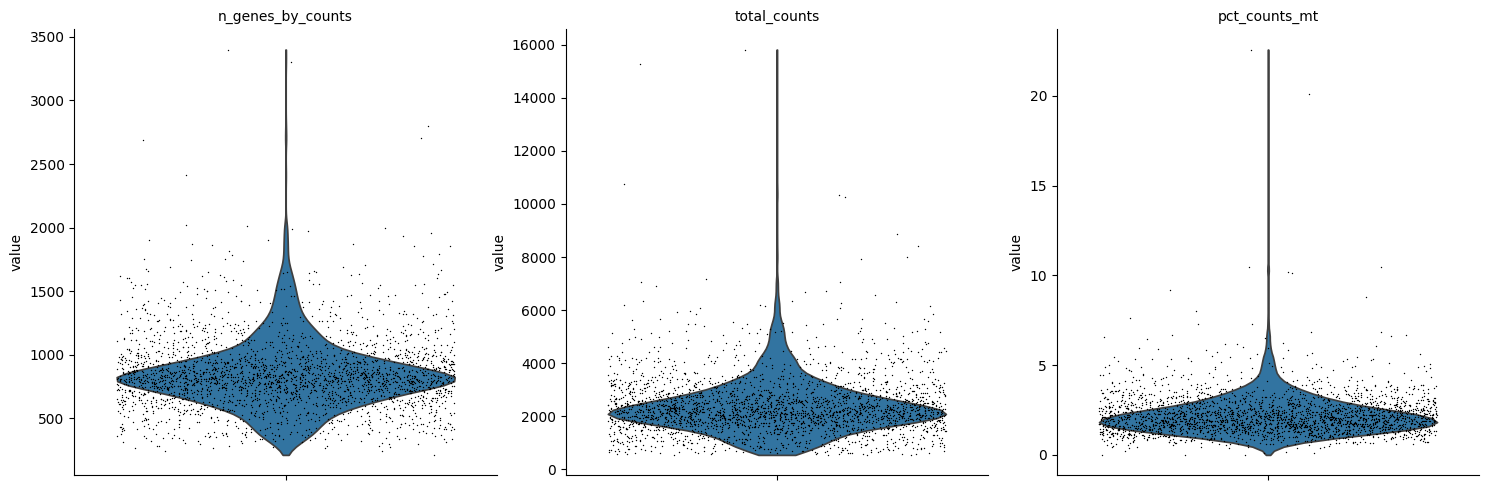

In [ ]:
#4 QC & filtering
adata.var_names_make_unique()
# filter low-quality genes
sc.pp.filter_genes(adata, min_cells=3)

# add mitochondrial genes
adata.var["mt"] = adata.var_names.str.startswith("MT-")

sc.pp.calculate_qc_metrics(
    adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True
)

# QC plots
sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True,
)

# filter cells
adata = adata[
    (adata.obs.n_genes_by_counts < 2500)
    & (adata.obs.n_genes_by_counts > 200)
    & (adata.obs.pct_counts_mt < 5),
    :,
].copy()

In [ ]:
#keeping raw counts
adata.layers["counts"] = adata.X.copy()

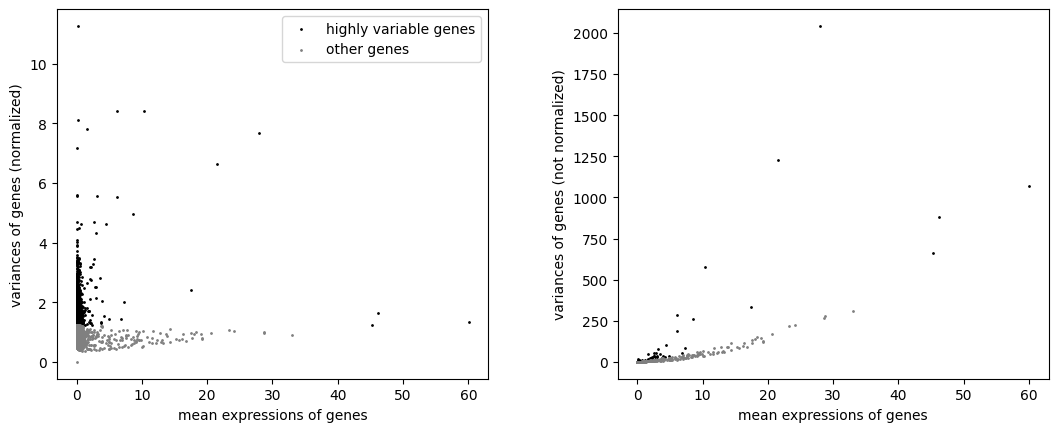

/usr/local/lib/python3.12/dist-packages/scanpy/preprocessing/_simple.py:667: NumbaPerformanceWarning: '@' is faster on contiguous arrays, called on (Array(float64, 1, 'A', False, aligned=True), Array(float64, 2, 'C', False, aligned=True))
  data[i] -= regressor[i] @ coeff
/usr/local/lib/python3.12/dist-packages/scanpy/preprocessing/_simple.py:667: NumbaPerformanceWarning: '@' is faster on contiguous arrays, called on (Array(float64, 1, 'A', False, aligned=True), Array(float64, 2, 'C', False, aligned=True))
  data[i] -= regressor[i] @ coeff


In [ ]:
#5 Normalization & HVG

sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

sc.pp.highly_variable_genes(
    adata,
    layer="counts",
    n_top_genes=2000,
    min_mean=0.0125,
    max_mean=3,
    min_disp=0.5,
    flavor="seurat_v3",
)

sc.pl.highly_variable_genes(adata)

# regression & scaling
adata.layers["scaled"] = adata.X.toarray()
sc.pp.regress_out(adata, ["total_counts", "pct_counts_mt"], layer="scaled")
sc.pp.scale(adata, max_value=10, layer="scaled")


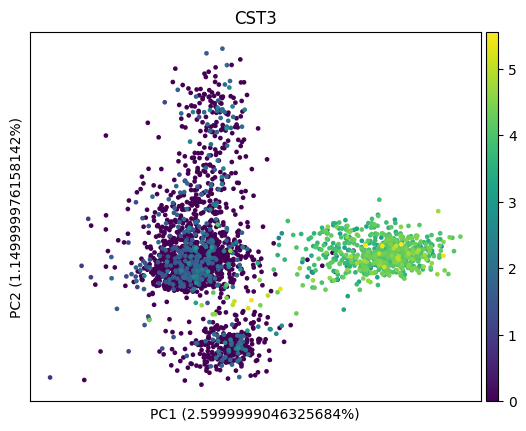

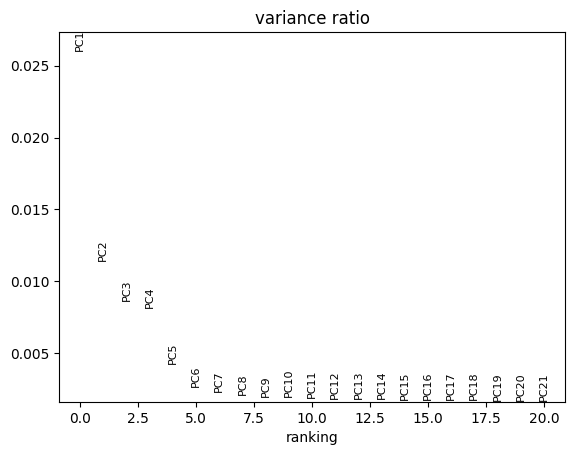

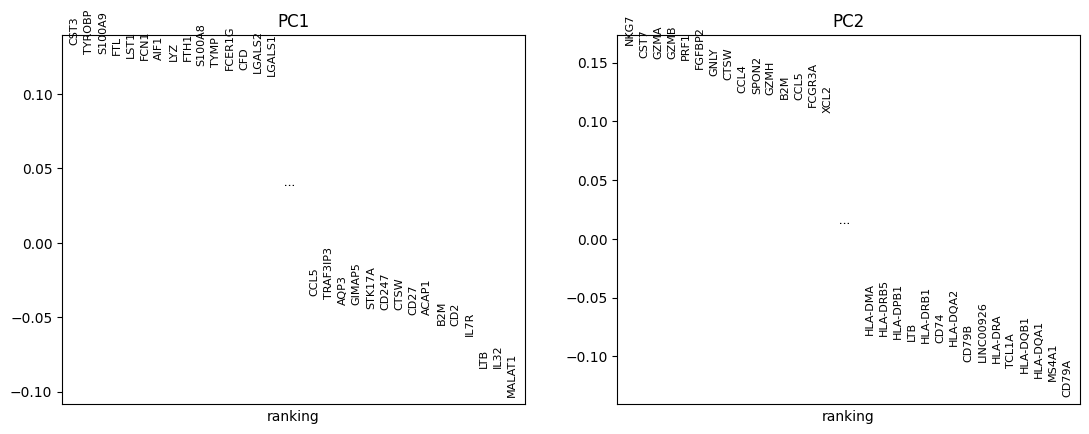

In [ ]:
#6 Dimensionality reduction

sc.pp.pca(adata, layer="scaled", svd_solver="arpack")
sc.pl.pca(adata, annotate_var_explained=True, color="CST3")
sc.pl.pca_variance_ratio(adata, n_pcs=20)
sc.pl.pca_loadings(adata, components=(1, 2), include_lowest=True)


/tmp/ipython-input-641199131.py:4: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata)


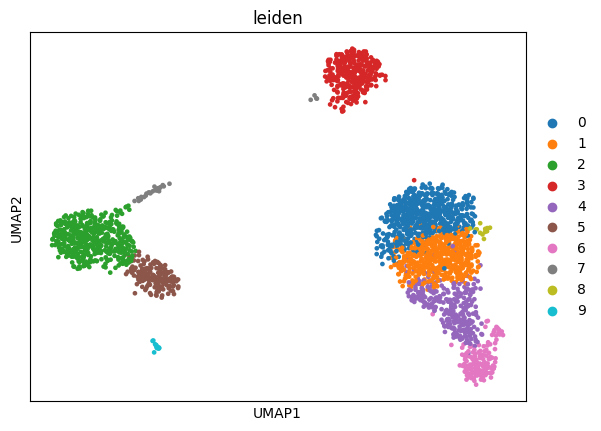

leiden
0    618
1    539
2    477
3    343
4    288
5    161
6    156
7     30
8     13
9     13
Name: count, dtype: int64


In [ ]:
#7 Neighbors & clustering

sc.pp.neighbors(adata, n_neighbors=10, n_pcs=40)
sc.tl.leiden(adata)
sc.tl.umap(adata)

sc.pl.umap(adata, color="leiden")

print(adata.obs["leiden"].value_counts())

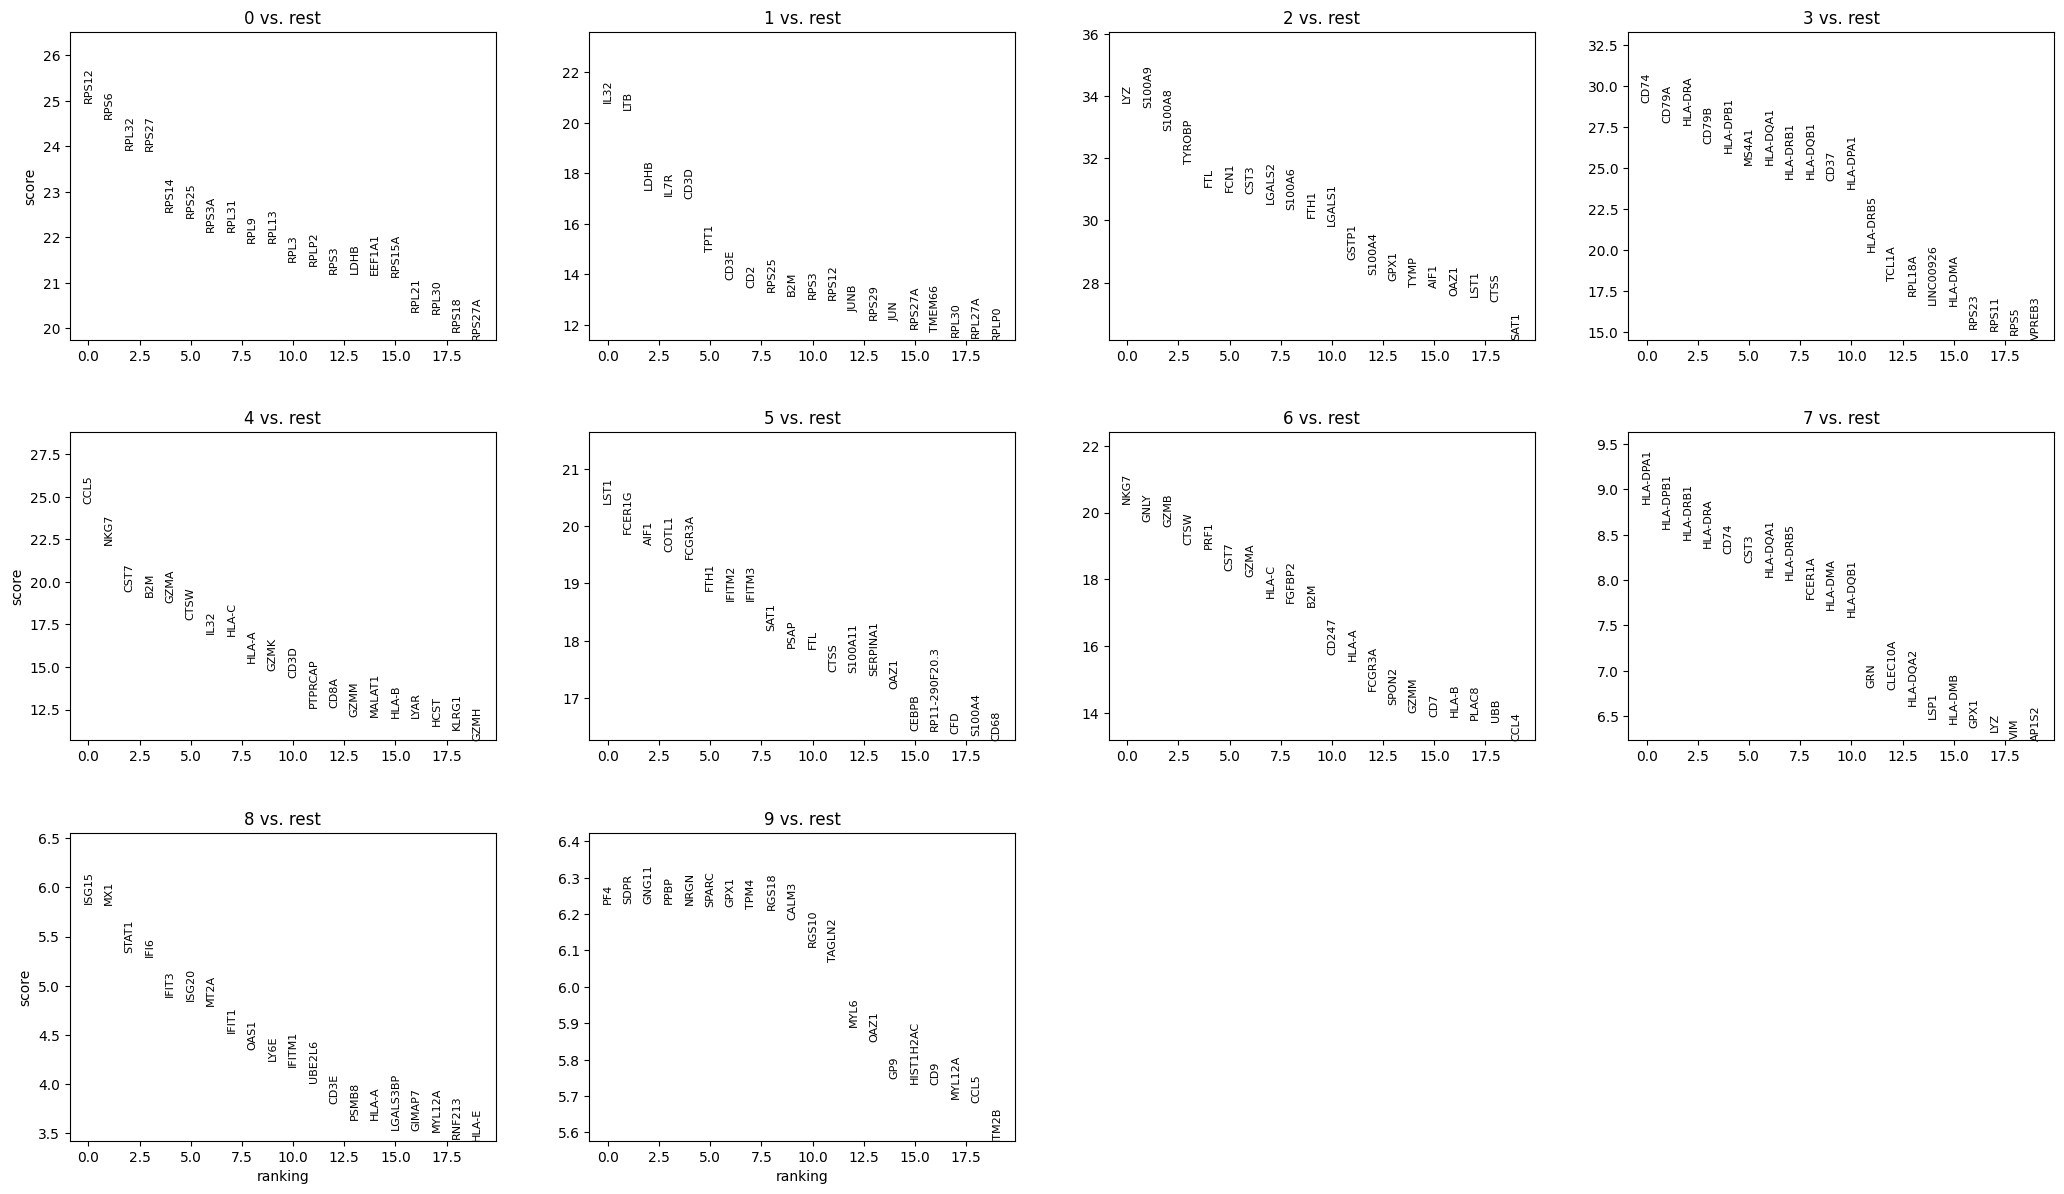

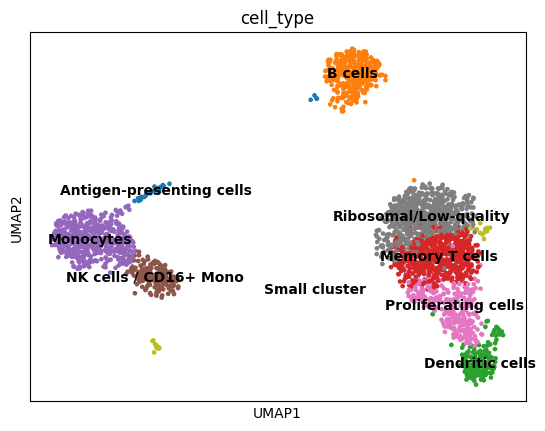

In [ ]:
#8 Marker genes

sc.tl.rank_genes_groups(adata, "leiden", method="wilcoxon")
sc.pl.rank_genes_groups(adata, n_genes=20, sharey=False)

# cluster annotations (example mapping)
cluster2annotation = {
    "0": "Ribosomal/Low-quality",
    "1": "Memory T cells",
    "2": "Monocytes",
    "3": "B cells",
    "4": "Proliferating cells",
    "5": "NK cells / CD16+ Mono",
    "6": "Dendritic cells",
    "7": "Antigen-presenting cells",
    "8": "Small cluster",
    "9": "Small cluster"
}
adata.obs["cell_type"] = adata.obs["leiden"].map(cluster2annotation)

sc.pl.umap(adata, color=["cell_type"], legend_loc="on data")


In [ ]:
#9 Machine learning example

# Features = HVGs
hvg_mask = adata.var['highly_variable'].values
X = adata[:, hvg_mask].X

# convert sparse -> dense
if sp.issparse(X):
    X = X.toarray()

# labels from clustering
y = adata.obs["leiden"].astype(str).values

# encode labels
le = LabelEncoder()
y_enc = le.fit_transform(y)

# split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc, test_size=0.2, stratify=y_enc, random_state=0
)

# pipeline
clf = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(
        multi_class="multinomial",
        solver="lbfgs",
        max_iter=200,
        class_weight="balanced",
        random_state=0
    ))
])
clf.fit(X_train, y_train)

# eval
y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred, target_names=le.classes_))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))

# interpret
coefs = clf.named_steps["logreg"].coef_
hvg_names = adata.var.index[hvg_mask]
for i, class_name in enumerate(le.classes_):
    top_idx = np.argsort(coefs[i])[-5:][::-1]
    print(f"\nTop genes for class {class_name}:")
    for j in top_idx:
        print(f"  {hvg_names[j]} (coef={coefs[i, j]:.2f})")


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


              precision    recall  f1-score   support

           0       0.80      0.73      0.76       124
           1       0.71      0.74      0.72       108
           2       0.99      1.00      0.99        95
           3       0.97      1.00      0.99        69
           4       0.85      0.91      0.88        58
           5       1.00      1.00      1.00        32
           6       0.94      0.97      0.95        31
           7       1.00      0.83      0.91         6
           8       1.00      0.33      0.50         3
           9       1.00      1.00      1.00         2

    accuracy                           0.87       528
   macro avg       0.93      0.85      0.87       528
weighted avg       0.87      0.87      0.87       528

Confusion matrix:
 [[91 28  0  2  3  0  0  0  0  0]
 [23 80  0  0  5  0  0  0  0  0]
 [ 0  0 95  0  0  0  0  0  0  0]
 [ 0  0  0 69  0  0  0  0  0  0]
 [ 0  3  0  0 53  0  2  0  0  0]
 [ 0  0  0  0  0 32  0  0  0  0]
 [ 0  0  0  0  1  0 30  

In [ ]:
#10 Enrichment analysis

os.makedirs("enrichr_all_clusters", exist_ok=True)
all_results = []

for cluster in adata.obs["leiden"].unique():
    print(f"Running enrichment for cluster {cluster}...")
    top_genes = adata.uns["rank_genes_groups"]["names"][cluster][:30].tolist()

    enr = gp.enrichr(
        gene_list=top_genes,
        gene_sets=["GO_Biological_Process_2023", "KEGG_2021_Human"],
        organism="Human",
        outdir=f"enrichr_all_clusters/cluster_{cluster}",
        cutoff=0.5
    )

    enr_res = enr.results.copy()
    enr_res["Cluster"] = cluster
    all_results.append(enr_res)

all_results_df = pd.concat(all_results, ignore_index=True)
all_results_df.to_csv("enrichr_all_clusters/all_clusters_enrichment.csv", index=False)

# filter significant
sig_results = all_results_df[all_results_df["Adjusted P-value"] < 0.05]
sig_results.to_csv("enrichr_all_clusters/significant_results.csv", index=False)


Running enrichment for cluster 4...
Running enrichment for cluster 3...
Running enrichment for cluster 1...
Running enrichment for cluster 2...
Running enrichment for cluster 6...
Running enrichment for cluster 5...
Running enrichment for cluster 0...
Running enrichment for cluster 8...
Running enrichment for cluster 7...
Running enrichment for cluster 9...


In [ ]:
# top 5 per cluster
top_pathways = (
    sig_results.sort_values(["Cluster", "Adjusted P-value"])
    .groupby("Cluster")
    .head(5)
)
top_pathways.to_csv("enrichr_all_clusters/top5_pathways_per_cluster.csv", index=False)
print(top_pathways[["Cluster", "Term", "Adjusted P-value", "Combined Score"]])

     Cluster                                               Term  \
2572       0               Cytoplasmic Translation (GO:0002181)   
2731       0                                           Ribosome   
2573       0          Peptide Biosynthetic Process (GO:0043043)   
2574       0    Macromolecule Biosynthetic Process (GO:0009059)   
2732       0                                Coronavirus disease   
756        1               Cytoplasmic Translation (GO:0002181)   
1053       1                                           Ribosome   
1054       1                                Coronavirus disease   
757        1          Peptide Biosynthetic Process (GO:0043043)   
758        1    Macromolecule Biosynthetic Process (GO:0009059)   
1136       2  Positive Regulation Of Response To External St...   
1137       2  Positive Regulation Of Defense Response (GO:00...   
1138       2  Positive Regulation Of Inflammatory Response (...   
1139       2            Microglial Cell Activation (GO:0001774

In [ ]:
 #11 Save
adata.write("scRNAseq_annotated.h5ad")

In [ ]:
!pip install scanpy anndata gdown

In [ ]:
!wget -O GSE290026_RAW.tar "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE290nnn/GSE290026/suppl/GSE290026_RAW.tar"

--2025-09-20 12:09:23--  https://ftp.ncbi.nlm.nih.gov/geo/series/GSE290nnn/GSE290026/suppl/GSE290026_RAW.tar
Resolving ftp.ncbi.nlm.nih.gov (ftp.ncbi.nlm.nih.gov)... 130.14.250.10, 130.14.250.11, 130.14.250.12, ...
Connecting to ftp.ncbi.nlm.nih.gov (ftp.ncbi.nlm.nih.gov)|130.14.250.10|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 562411520 (536M) [application/x-tar]
Saving to: ‘GSE290026_RAW.tar’

GSE290026_RAW.tar   100%[===================>] 536.36M  13.4MB/s    in 31s     

2025-09-20 12:09:56 (17.1 MB/s) - ‘GSE290026_RAW.tar’ saved [562411520/562411520]



In [ ]:
import tarfile

# Extract the TAR into a folder
tar_path = "GSE290026_RAW.tar"
extract_dir = "GSE290026_RAW"

with tarfile.open(tar_path, "r") as tar:
    tar.extractall(extract_dir)

print("Files extracted to:", extract_dir

SyntaxError: incomplete input (ipython-input-4293259193.py, line 10)

In [ ]:
import os

for root, dirs, files in os.walk(extract_dir):
    for file in files:
        print(os.path.join(root, file))

In [ ]:
import scanpy as sc

sample_dir = f"{extract_dir}/GSM8804011_CR_BASELINE_Patient_01"

adata = sc.read_10x_mtx(
    sample_dir,
    var_names="gene_symbols",   # or "gene_ids" if features.tsv.gz doesn’t have symbols
    cache=True
)

print(adata)